In [239]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [240]:
df = pd.read_csv("../data/bank-full.csv", sep=";")

In [241]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [242]:
df.shape



(45211, 17)

In [243]:
df.shape

(45211, 17)

In [244]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [245]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [246]:
df.duplicated().sum()

np.int64(0)

In [247]:
categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    print(f"\n{col}")
    print(df[col].value_counts())


job
job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64

marital
marital
married     27214
single      12790
divorced     5207
Name: count, dtype: int64

education
education
secondary    23202
tertiary     13301
primary       6851
unknown       1857
Name: count, dtype: int64

default
default
no     44396
yes      815
Name: count, dtype: int64

housing
housing
yes    25130
no     20081
Name: count, dtype: int64

loan
loan
no     37967
yes     7244
Name: count, dtype: int64

contact
contact
cellular     29285
unknown      13020
telephone     2906
Name: count, dtype: int64

month
month
may    13766
jul     6895
aug     6247
jun     5341
nov     3970
apr     2932
feb     2649
jan     1403
oct      738
sep      579
mar      477
dec      214
Name: count

In [248]:
df["y"].value_counts(normalize=True) * 100

y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64

In [249]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [250]:
df[["age", "balance", "duration", "campaign", "pdays", "previous"]].describe().T

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


In [251]:
print("pdays = -1:", (df["pdays"] == -1).sum())
print("balance < 0:", (df["balance"] < 0).sum())

pdays = -1: 36954
balance < 0: 3766


In [252]:
df["subscribed"] = df["y"].map({"yes": 1, "no": 0})

In [253]:
job_response = (
    df.groupby("job")["subscribed"]
      .agg(["count", "sum", "mean"])
      .sort_values("mean", ascending=False)
)

job_response

,count,sum,mean
job,,,
student,938,269,0.286780
retired,2264,516,0.227915
unemployed,1303,202,0.155027
management,9458,1301,0.137556
admin.,5171,631,0.122027
self-employed,1579,187,0.118429
unknown,288,34,0.118056
technician,7597,840,0.110570
services,4154,369,0.088830


In [254]:
job_response["response_rate_%"] = (
    job_response["mean"] * 100
).round(2)

job_response

,count,sum,mean,response_rate_%
job,,,,
student,938,269,0.286780,28.68
retired,2264,516,0.227915,22.79
unemployed,1303,202,0.155027,15.50
management,9458,1301,0.137556,13.76
admin.,5171,631,0.122027,12.20
self-employed,1579,187,0.118429,11.84
unknown,288,34,0.118056,11.81
technician,7597,840,0.110570,11.06
services,4154,369,0.088830,8.88


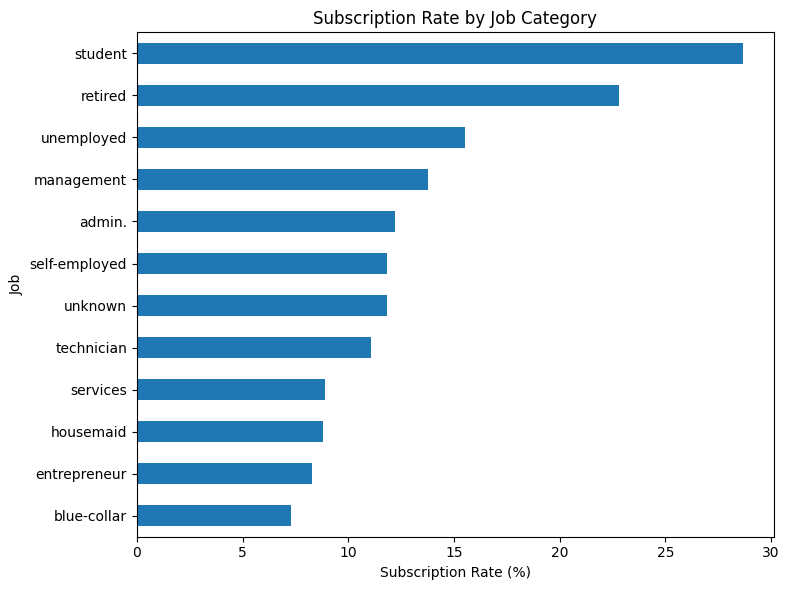

In [255]:
job_response["response_rate_%"].sort_values().plot(
    kind="barh",
    figsize=(8, 6)
)

plt.xlabel("Subscription Rate (%)")
plt.ylabel("Job")
plt.title("Subscription Rate by Job Category")
plt.tight_layout()
plt.savefig("../images/subscription_rate_by_job.png", dpi=300, bbox_inches="tight")
plt.show()

In [256]:
education_response = (
    df.groupby("education")["subscribed"]
      .agg(["count", "sum", "mean"])
      .sort_values("mean", ascending=False)
)

education_response["response_rate_%"] = (
    education_response["mean"] * 100
).round(2)

education_response

,count,sum,mean,response_rate_%
education,,,,
tertiary,13301,1996,0.150064,15.01
unknown,1857,252,0.135703,13.57
secondary,23202,2450,0.105594,10.56
primary,6851,591,0.086265,8.63


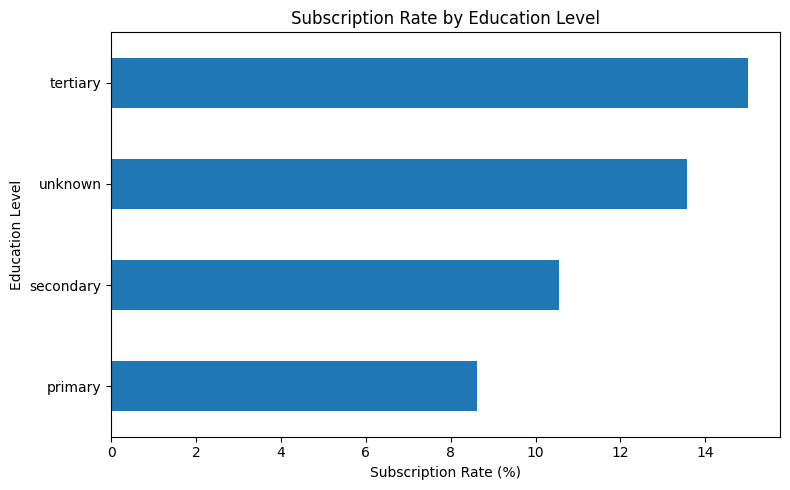

In [257]:
education_response["response_rate_%"].sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.xlabel("Subscription Rate (%)")
plt.ylabel("Education Level")
plt.title("Subscription Rate by Education Level")
plt.tight_layout()
plt.show()

In [258]:
housing_response = (
    df.groupby("housing")["subscribed"]
      .agg(["count", "sum", "mean"])
      .sort_values("mean", ascending=False)
)

housing_response["response_rate_%"] = (
    housing_response["mean"] * 100
).round(2)

housing_response

,count,sum,mean,response_rate_%
housing,,,,
no,20081,3354,0.167024,16.7
yes,25130,1935,0.077000,7.7


In [259]:
loan_response = (
    df.groupby("loan")["subscribed"]
      .agg(["count", "sum", "mean"])
      .sort_values("mean", ascending=False)
)

loan_response["response_rate_%"] = (
    loan_response["mean"] * 100
).round(2)

loan_response

,count,sum,mean,response_rate_%
loan,,,,
no,37967,4805,0.126557,12.66
yes,7244,484,0.066814,6.68


In [260]:
poutcome_response = (
    df.groupby("poutcome")["subscribed"]
      .agg(["count", "sum", "mean"])
      .sort_values("mean", ascending=False)
)

poutcome_response["response_rate_%"] = (
    poutcome_response["mean"] * 100
).round(2)

poutcome_response

,count,sum,mean,response_rate_%
poutcome,,,,
success,1511,978,0.647253,64.73
other,1840,307,0.166848,16.68
failure,4901,618,0.126097,12.61
unknown,36959,3386,0.091615,9.16


In [261]:
df["campaign"].value_counts().sort_index()

campaign
1     17544
2     12505
3      5521
4      3522
5      1764
6      1291
7       735
8       540
9       327
10      266
11      201
12      155
13      133
14       93
15       84
16       79
17       69
18       51
19       44
20       43
21       35
22       23
23       22
24       20
25       22
26       13
27       10
28       16
29       16
30        8
31       12
32        9
33        6
34        5
35        4
36        4
37        2
38        3
39        1
41        2
43        3
44        1
46        1
50        2
51        1
55        1
58        1
63        1
Name: count, dtype: int64

In [262]:
df["campaign_group"] = pd.cut(
    df["campaign"],
    bins=[0, 1, 2, 3, 5, 10, float("inf")],
    labels=["1", "2", "3", "4-5", "6-10", "11+"]
)

In [263]:
campaign_response = (
    df.groupby("campaign_group", observed=False)["subscribed"]
      .agg(["count", "sum", "mean"])
)

campaign_response["response_rate_%"] = (
    campaign_response["mean"] * 100
).round(2)

campaign_response

,count,sum,mean,response_rate_%
campaign_group,,,,
1,17544,2561,0.145976,14.60
2,12505,1401,0.112035,11.20
3,5521,618,0.111936,11.19
4-5,5286,456,0.086266,8.63
6-10,3159,206,0.065211,6.52
11+,1196,47,0.039298,3.93


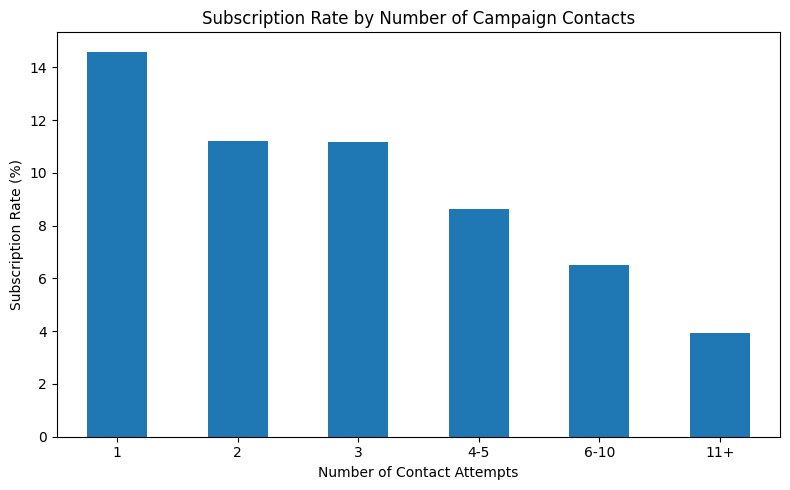

In [264]:
campaign_response["response_rate_%"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.xlabel("Number of Contact Attempts")
plt.ylabel("Subscription Rate (%)")
plt.title("Subscription Rate by Number of Campaign Contacts")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../images/subscription_rate_by_campaign_contacts.png", dpi=300, bbox_inches="tight")
plt.show()

In [265]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[17, 29, 39, 49, 59, 69, 100],
    labels=["18-29", "30-39", "40-49", "50-59", "60-69", "70+"]
)

In [266]:
age_response = (
    df.groupby("age_group", observed=False)["subscribed"]
      .agg(["count", "sum", "mean"])
)

age_response["response_rate_%"] = (
    age_response["mean"] * 100
).round(2)

age_response

,count,sum,mean,response_rate_%
age_group,,,,
18-29,5273,928,0.175991,17.60
30-39,18089,1913,0.105755,10.58
40-49,11655,1063,0.091205,9.12
50-59,8410,785,0.093341,9.33
60-69,1230,365,0.296748,29.67
70+,554,235,0.424188,42.42


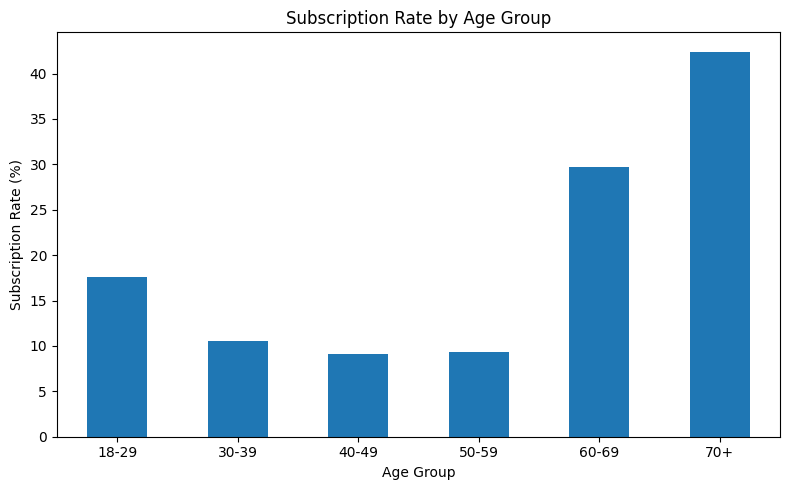

In [267]:
age_response["response_rate_%"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.xlabel("Age Group")
plt.ylabel("Subscription Rate (%)")
plt.title("Subscription Rate by Age Group")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../images/subscription_rate_by_age.png", dpi=300, bbox_inches="tight")
plt.show()

In [268]:
df["balance_group"] = pd.qcut(
    df["balance"],
    q=4,
    labels=["Q1 Lowest", "Q2", "Q3", "Q4 Highest"]
)

In [269]:
balance_response = (
    df.groupby("balance_group", observed=False)["subscribed"]
      .agg(["count", "sum", "mean"])
)

balance_response["response_rate_%"] = (
    balance_response["mean"] * 100
).round(2)

balance_response

,count,sum,mean,response_rate_%
balance_group,,,,
Q1 Lowest,11317,819,0.072369,7.24
Q2,11291,1230,0.108936,10.89
Q3,11306,1415,0.125155,12.52
Q4 Highest,11297,1825,0.161547,16.15


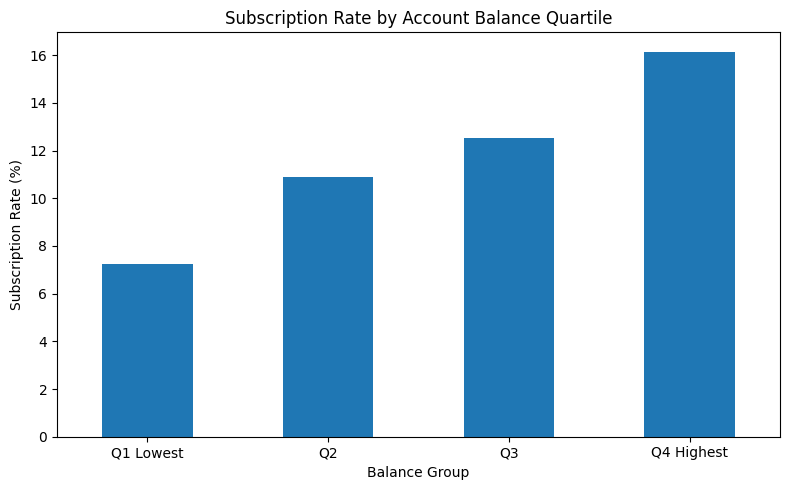

In [270]:
balance_response["response_rate_%"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.xlabel("Balance Group")
plt.ylabel("Subscription Rate (%)")
plt.title("Subscription Rate by Account Balance Quartile")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../images/subscription_rate_by_balance.png", dpi=300, bbox_inches="tight")
plt.show()

In [271]:
contact_response = (
    df.groupby("contact")["subscribed"]
      .agg(["count", "sum", "mean"])
      .sort_values("mean", ascending=False)
)

contact_response["response_rate_%"] = (
    contact_response["mean"] * 100
).round(2)

contact_response

,count,sum,mean,response_rate_%
contact,,,,
cellular,29285,4369,0.149189,14.92
telephone,2906,390,0.134205,13.42
unknown,13020,530,0.040707,4.07


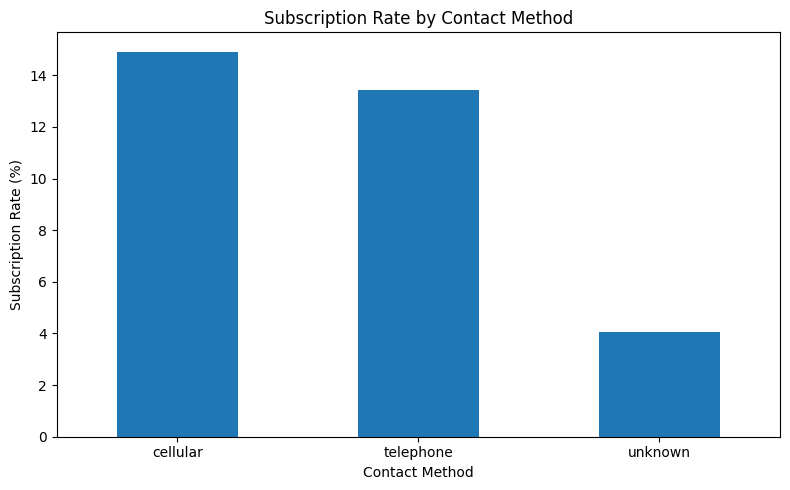

In [272]:
contact_response["response_rate_%"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.xlabel("Contact Method")
plt.ylabel("Subscription Rate (%)")
plt.title("Subscription Rate by Contact Method")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [273]:
month_response = (
    df.groupby("month")["subscribed"]
      .agg(["count", "sum", "mean"])
      .sort_values("mean", ascending=False)
)

month_response["response_rate_%"] = (
    month_response["mean"] * 100
).round(2)

month_response

,count,sum,mean,response_rate_%
month,,,,
mar,477,248,0.519916,51.99
dec,214,100,0.467290,46.73
sep,579,269,0.464594,46.46
oct,738,323,0.437669,43.77
apr,2932,577,0.196794,19.68
feb,2649,441,0.166478,16.65
aug,6247,688,0.110133,11.01
jun,5341,546,0.102228,10.22
nov,3970,403,0.101511,10.15


In [274]:
month_order = [
    "jan", "feb", "mar", "apr", "may", "jun",
    "jul", "aug", "sep", "oct", "nov", "dec"
]

month_response = month_response.reindex(month_order)

month_response

,count,sum,mean,response_rate_%
month,,,,
jan,1403,142,0.101212,10.12
feb,2649,441,0.166478,16.65
mar,477,248,0.519916,51.99
apr,2932,577,0.196794,19.68
may,13766,925,0.067195,6.72
jun,5341,546,0.102228,10.22
jul,6895,627,0.090935,9.09
aug,6247,688,0.110133,11.01
sep,579,269,0.464594,46.46


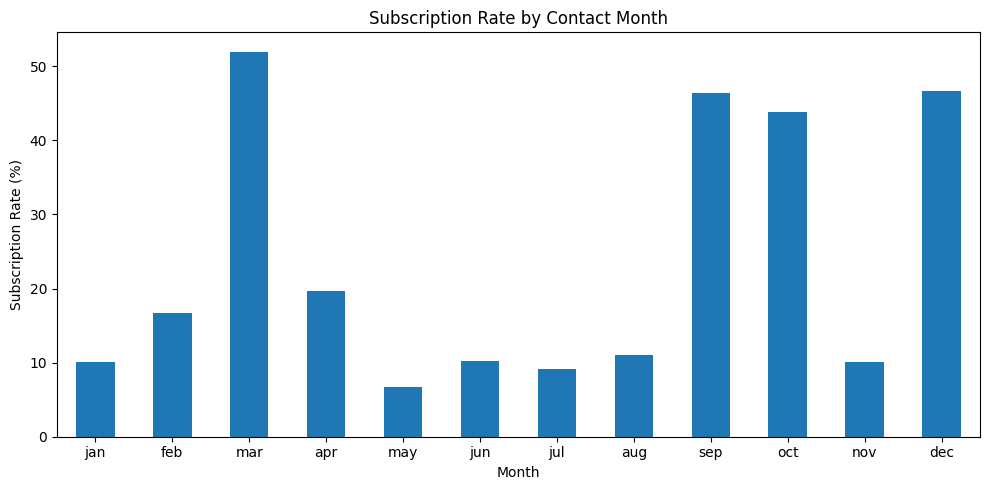

In [275]:
month_response["response_rate_%"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.xlabel("Month")
plt.ylabel("Subscription Rate (%)")
plt.title("Subscription Rate by Contact Month")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../images/subscription_rate_by_month.png", dpi=300, bbox_inches="tight")
plt.show()

## Checkpoint 1 — Data Understanding and Exploratory Analysis
### Dataset Overview

The Bank Marketing dataset contains **45,211 customer records and 17 original variables**. Initial data-quality checks found:

- No conventional missing values (`NaN`)
- No duplicate rows
- 7 numeric variables and 10 categorical variables
- Some categorical fields contain `"unknown"`, which was retained as a valid recorded category rather than treated automatically as missing data

The target variable `y` records whether a customer subscribed to the term deposit.

- **Subscribers:** 5,289
- **Non-subscribers:** 39,922
- **Overall subscription rate:** approximately **11.7%**

This indicates a moderately imbalanced target, with most customers not subscribing.

---

### Key Exploratory Findings

#### Job

Subscription rates varied by occupation.

- Students: **26.88%**
- Retired: **22.79%**
- Unemployed: **15.50%**
- Management: **13.76%**
- Blue-collar: **7.28%**

Students and retired customers had relatively high response rates, although their sample sizes were smaller than large groups such as management and blue-collar customers.

---

#### Education

Response rates also differed by education level.

- Tertiary: **15.01%**
- Unknown: **13.57%**
- Secondary: **10.56%**
- Primary: **8.63%**

Customers with tertiary education showed the highest subscription rate among the known education groups.

---

#### Housing and Personal Loans

Customers without existing loans responded more strongly.

**Housing loan**

- No housing loan: **16.70%**
- Housing loan: **7.70%**

**Personal loan**

- No personal loan: **12.66%**
- Personal loan: **6.68%**

This suggests that customers with existing debt obligations were less responsive to the campaign.

---

#### Previous Campaign Outcome

Previous campaign success was one of the strongest descriptive signals.

- Previous success: **64.73%**
- Other: **16.68%**
- Previous failure: **12.61%**
- Unknown: **9.16%**

Customers who had responded successfully to an earlier campaign were substantially more likely to subscribe again.

---

#### Number of Campaign Contacts

Subscription rates generally declined as the number of contact attempts increased.

- 1 contact: **14.60%**
- 2 contacts: **11.20%**
- 3 contacts: **11.19%**
- 4–5 contacts: **8.63%**
- 6–10 contacts: **6.52%**
- 11+ contacts: **3.93%**

Repeated contact was associated with diminishing conversion efficiency. However, this should not automatically be interpreted as repeated contact causing rejection, because harder-to-convert customers may naturally receive more follow-ups.

---

#### Age

Age showed a non-linear relationship with subscription.

- 18–29: **17.60%**
- 30–39: **10.58%**
- 40–49: **9.12%**
- 50–59: **9.33%**
- 60–69: **29.67%**
- 70+: **42.42%**

Older customers had particularly high response rates, while younger customers also performed better than the middle-age groups.

---

#### Account Balance

Subscription rates increased progressively across balance quartiles.

- Q1 Lowest: **7.24%**
- Q2: **10.89%**
- Q3: **12.52%**
- Q4 Highest: **16.15%**

Customers with higher account balances were more likely to subscribe.

---

#### Contact Method

Known contact methods performed substantially better than unknown contact methods.

- Cellular: **14.92%**
- Telephone: **13.42%**
- Unknown: **4.07%**

Cellular contact produced the highest response rate.

---

#### Contact Month

Response rates varied considerably across months.

High-performing months included:

- March: **51.99%**
- December: **46.73%**
- September: **46.46%**
- October: **43.77%**

However, some of these months contained relatively small numbers of customers. This highlights an important analytical principle:

> **Rates should always be interpreted together with sample size.**

A high percentage based on a small number of observations may be much less reliable than a slightly lower percentage based on a much larger group.

---

### Checkpoint 1 Summary

The exploratory analysis identified several variables associated with campaign response, particularly **previous campaign outcome, age group, account balance, loan status, contact method, occupation, and number of campaign contacts**.

These findings are descriptive and do not prove causation. The next stage uses statistical tests to determine whether selected observed relationships are statistically significant and to measure their strength.

In [276]:
housing_table = pd.crosstab(df["housing"], df["y"])

housing_table

y,no,yes
housing,,
no,16727,3354
yes,23195,1935


In [277]:
from scipy.stats import chi2_contingency

chi2, p, dof, expected = chi2_contingency(housing_table)

print("Chi-square:", chi2)
print("p-value:", p)
print("Degrees of freedom:", dof)

Chi-square: 874.822448867983
p-value: 2.918797605076633e-192
Degrees of freedom: 1


In [278]:
import numpy as np

n = housing_table.to_numpy().sum()

cramers_v = np.sqrt(chi2 / n)

print("Cramer's V:", cramers_v)

Cramer's V: 0.1391034505051807


In [279]:
loan_table = pd.crosstab(df["loan"], df["y"])

loan_table

y,no,yes
loan,,
no,33162,4805
yes,6760,484


In [280]:
chi2_loan, p_loan, dof_loan, expected_loan = chi2_contingency(loan_table)

print("Chi-square:", chi2_loan)
print("p-value:", p_loan)
print("Degrees of freedom:", dof_loan)

Chi-square: 209.61698034978633
p-value: 1.665061163492756e-47
Degrees of freedom: 1


In [281]:
n_loan = loan_table.to_numpy().sum()

cramers_v_loan = np.sqrt(chi2_loan / n_loan)

print("Cramer's V:", cramers_v_loan)

Cramer's V: 0.06809122911100252


In [282]:
poutcome_table = pd.crosstab(df["poutcome"], df["y"])

poutcome_table

y,no,yes
poutcome,,
failure,4283,618
other,1533,307
success,533,978
unknown,33573,3386


In [283]:
chi2_poutcome, p_poutcome, dof_poutcome, expected_poutcome = chi2_contingency(poutcome_table)

print("Chi-square:", chi2_poutcome)
print("p-value:", p_poutcome)
print("Degrees of freedom:", dof_poutcome)

Chi-square: 4391.5065887686615
p-value: 0.0
Degrees of freedom: 3


In [284]:
n_poutcome = poutcome_table.to_numpy().sum()

rows, cols = poutcome_table.shape

cramers_v_poutcome = np.sqrt(
    chi2_poutcome / (n_poutcome * min(rows - 1, cols - 1))
)

print("Cramer's V:", cramers_v_poutcome)

Cramer's V: 0.3116626167998104


In [285]:
education_table = pd.crosstab(df["education"], df["y"])

education_table

y,no,yes
education,,
primary,6260,591
secondary,20752,2450
tertiary,11305,1996
unknown,1605,252


In [286]:
chi2_education, p_education, dof_education, expected_education = chi2_contingency(education_table)

print("Chi-square:", chi2_education)
print("p-value:", p_education)
print("Degrees of freedom:", dof_education)

Chi-square: 238.92350616407606
p-value: 1.6266562124072994e-51
Degrees of freedom: 3


In [287]:
n_education = education_table.to_numpy().sum()

rows, cols = education_table.shape

cramers_v_education = np.sqrt(
    chi2_education / (n_education * min(rows - 1, cols - 1))
)

print("Cramer's V:", cramers_v_education)

Cramer's V: 0.07269547575269042


In [288]:
balance_by_subscription = (
    df.groupby("y")["balance"]
      .agg(["count", "mean", "median", "std"])
)

balance_by_subscription

,count,mean,median,std
y,,,,
no,39922,1303.714969,417.0,2974.195473
yes,5289,1804.267915,733.0,3501.104777


In [289]:
from scipy.stats import mannwhitneyu

balance_yes = df.loc[df["y"] == "yes", "balance"]
balance_no = df.loc[df["y"] == "no", "balance"]

u_stat, p_balance = mannwhitneyu(
    balance_yes,
    balance_no,
    alternative="two-sided"
)

print("Mann-Whitney U:", u_stat)
print("p-value:", p_balance)

Mann-Whitney U:

 124589983.5
p-value: 6.593845808689515e-101


In [290]:
n_yes = len(balance_yes)
n_no = len(balance_no)

r_balance = 1 - (2 * u_stat) / (n_yes * n_no)

print("Effect size:", r_balance)

Effect size: -0.18012297832162383


In [291]:
age_by_subscription = (
    df.groupby("y")["age"]
      .agg(["count", "mean", "median", "std"])
)

age_by_subscription

,count,mean,median,std
y,,,,
no,39922,40.838986,39.0,10.172662
yes,5289,41.670070,38.0,13.497781


In [292]:
age_yes = df.loc[df["y"] == "yes", "age"]
age_no = df.loc[df["y"] == "no", "age"]

u_age, p_age = mannwhitneyu(
    age_yes,
    age_no,
    alternative="two-sided"
)

print("Mann-Whitney U:", u_age)
print("p-value:", p_age)

Mann-Whitney U: 103915109.5
p-value: 0.06281791018697587


In [293]:
n_age_yes = len(age_yes)
n_age_no = len(age_no)

r_age = (2 * u_age) / (n_age_yes * n_age_no) - 1

print("Effect size:", r_age)

Effect size: -0.015710532494310203


## Checkpoint 2 — Statistical Testing

### Purpose

Statistical testing was used to move beyond descriptive differences and determine whether selected relationships were statistically significant and how strong those relationships were.

Two main approaches were used:

- **Chi-square test of independence** for categorical variables
- **Mann–Whitney U test** for numeric variables

Effect sizes were also calculated because statistical significance alone does not indicate the strength of a relationship.

---

### Chi-Square Tests

The Chi-square test was used to test whether categorical variables were associated with subscription outcome.

The general interpretation was:

- **p < 0.05** → evidence of an association
- **p ≥ 0.05** → insufficient evidence to reject independence

Because the dataset is large, very small p-values can occur even for weak relationships. Therefore, **Cramér's V** was used to measure association strength.

#### Housing Loan

- Chi-square ≈ **874.82**
- p < **0.001**
- Cramér's V ≈ **0.139**

Housing-loan status was statistically associated with subscription outcome, but the association was relatively small.

---

#### Personal Loan

- Chi-square ≈ **209.62**
- p < **0.001**
- Cramér's V ≈ **0.068**

Personal-loan status was statistically significant but had a very weak association with subscription.

---

#### Previous Campaign Outcome

- Chi-square ≈ **4391.51**
- p < **0.001**
- Cramér's V ≈ **0.312**

Previous campaign outcome showed a moderate association with current subscription and was substantially stronger than housing-loan or personal-loan status.

---

#### Education

- Chi-square ≈ **238.92**
- p < **0.001**
- Cramér's V ≈ **0.073**

Education level was statistically associated with subscription, but the association was weak.

---

### Mann–Whitney U Tests

The Mann–Whitney U test was used to compare numeric variables between subscribers and non-subscribers.

Unlike Chi-square, which tests association between categorical variables, Mann–Whitney asks whether values of a numeric variable tend to differ systematically between two groups.

---

#### Account Balance

Subscribers had higher account balances than non-subscribers.

- Non-subscriber median balance: **417**
- Subscriber median balance: **733**
- p-value < **0.001**
- Effect size ≈ **0.18**

The difference was statistically significant, although the effect size was small.

This supports the earlier EDA finding that subscription rates increased across account-balance quartiles.

---

#### Age

- Non-subscriber mean age: approximately **40.84**
- Subscriber mean age: approximately **41.67**
- Mann–Whitney p-value ≈ **0.063**
- Effect size ≈ **0.016**

The overall age distributions were not significantly different at the 5% level, and the effect size was negligible.

However, the earlier age-group analysis showed a clear non-linear pattern, with relatively high response rates among younger customers and especially customers aged 60+.

This illustrates that a simple two-group comparison can sometimes hide non-linear relationships.

---

### Key Statistical Lessons

1. **A small p-value does not mean a strong relationship.**

   The p-value indicates whether there is evidence against the null hypothesis.

2. **Effect size measures strength.**

   Statistical significance and practical importance are not the same thing.

3. **Large samples can produce extremely small p-values even for weak relationships.**

4. **The meaning of a p-value depends on the statistical test being used.**

   - Chi-square: tests association between categorical variables.
   - Mann–Whitney: tests whether a numeric variable tends to differ between two groups.

---

### Checkpoint 2 Summary

The strongest categorical statistical relationship identified was **previous campaign outcome**, with a moderate Cramér's V.

Housing-loan, personal-loan, and education variables were statistically significant but showed relatively weak associations.

Account balance differed significantly between subscribers and non-subscribers, although the effect size was small.

Age showed no significant overall difference between subscribers and non-subscribers, despite the non-linear pattern observed in the age-group analysis.

The next stage uses these variables together in a logistic regression model to estimate subscription probability.

In [294]:
model_df = df.drop(columns=[
    "y",
    "duration",
    "subscribed"
]).copy()

In [295]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [296]:
df = pd.read_csv("../data/bank-full.csv", sep=";")

In [297]:
df["subscribed"] = df["y"].map({"yes": 1, "no": 0})

In [298]:
target = df["y"].map({"yes": 1, "no": 0})

model_df = df.drop(columns=[
    "y",
    "duration"
]).copy()

In [299]:
model_df.shape

(45211, 16)

In [300]:
model_df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,subscribed
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,1,-1,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,1,-1,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,1,-1,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,1,-1,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,1,-1,0,unknown,0


In [301]:
target = df["y"].map({"yes": 1, "no": 0})

model_df = df.drop(columns=[
    "y",
    "duration",
    "subscribed"
]).copy()

In [302]:
target = df["y"].map({"yes": 1, "no": 0})

model_df = df.drop(columns=[
    "y",
    "duration"
]).copy()

In [303]:
model_df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,subscribed
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,1,-1,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,1,-1,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,1,-1,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,1,-1,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,1,-1,0,unknown,0


In [304]:
model_df.shape

(45211, 16)

In [305]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    model_df,
    target,
    test_size=0.2,
    random_state=42,
    stratify=target
)

In [306]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (36168, 16)
X_test: (9043, 16)
y_train: (36168,)
y_test: (9043,)


In [307]:
print("Training target proportions:")
print(y_train.value_counts(normalize=True))

print("\nTest target proportions:")
print(y_test.value_counts(normalize=True))

Training target proportions:
y
0    0.883018
1    0.116982
Name: proportion, dtype: float64

Test target proportions:
y
0    0.883003
1    0.116997
Name: proportion, dtype: float64


In [308]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = [
    "age",
    "balance",
    "day",
    "campaign",
    "pdays",
    "previous"
]

categorical_features = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "poutcome"
]

In [309]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [310]:
("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)

('cat',
 OneHotEncoder(handle_unknown='ignore'),
 ['job',
  'marital',
  'education',
  'default',
  'housing',
  'loan',
  'contact',
  'month',
  'poutcome'])

In [311]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

In [312]:
logistic_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [313]:
print("Model training complete.")

Model training complete.


In [314]:
y_pred = logistic_model.predict(X_test)

In [315]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8932876257879022

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.99      0.94      7985
           1       0.66      0.18      0.28      1058

    accuracy                           0.89      9043
   macro avg       0.78      0.58      0.61      9043
weighted avg       0.87      0.89      0.87      9043


Confusion Matrix:
[[7889   96]
 [ 869  189]]


In [316]:
y_prob = logistic_model.predict_proba(X_test)[:, 1]

In [317]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.7717487775401183


In [318]:
threshold = 0.30

y_pred_30 = (y_prob >= threshold).astype(int)

In [319]:
print(classification_report(y_test, y_pred_30))

print(confusion_matrix(y_test, y_pred_30))

              precision    recall  f1-score   support

           0       0.92      0.96      0.94      7985
           1       0.56      0.33      0.42      1058

    accuracy                           0.89      9043
   macro avg       0.74      0.65      0.68      9043
weighted avg       0.87      0.89      0.88      9043

[[7703  282]
 [ 706  352]]


In [320]:
feature_names = logistic_model.named_steps["preprocessor"].get_feature_names_out()

In [321]:
coefficients = logistic_model.named_steps["classifier"].coef_[0]

In [322]:
coef_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

In [323]:
coef_df.sort_values("coefficient", ascending=False).head(15)

,feature,coefficient
48,cat__poutcome_success,1.477879
41,cat__month_mar,1.116231
45,cat__month_sep,0.726350
44,cat__month_oct,0.671800
36,cat__month_dec,0.643137
11,cat__job_retired,0.401235
31,cat__contact_cellular,0.345240
14,cat__job_student,0.297690
40,cat__month_jun,0.243558
32,cat__contact_telephone,0.165813


In [324]:
coef_df.sort_values("coefficient").head(15)

,feature,coefficient
38,cat__month_jan,-1.048646
33,cat__contact_unknown,-0.978533
43,cat__month_nov,-0.799364
46,cat__poutcome_failure,-0.785559
35,cat__month_aug,-0.768251
49,cat__poutcome_unknown,-0.653835
39,cat__month_jul,-0.632087
47,cat__poutcome_other,-0.505964
28,cat__housing_yes,-0.492248
30,cat__loan_yes,-0.422609


## Checkpoint 3 — Logistic Regression Modelling

### Objective

A logistic regression model was built to estimate the probability that a customer would subscribe to a term deposit.

The goal was not to build a production-grade model, but to create an interpretable baseline model that could support customer targeting.

---

### Data Preparation

The target variable was converted to binary form:

- `yes` → 1
- `no` → 0

The `duration` variable was excluded from modelling because call duration is only known after the marketing call takes place. Including it would introduce **data leakage** and make the model unrealistic for pre-campaign targeting.

The data was split into:

- **80% training data**
- **20% test data**

Stratification was used to preserve the original class proportions in both sets.

---

### Preprocessing

Numeric features were standardized using `StandardScaler`.

Categorical features were converted into binary indicator variables using `OneHotEncoder`.

The preprocessing and logistic regression model were combined inside a Scikit-learn pipeline.

---

### Class Imbalance

The subscription outcome was imbalanced:

- Approximately **88.3%** did not subscribe
- Approximately **11.7%** subscribed

This meant that accuracy alone could be misleading.

A model predicting `"no"` for every customer would already achieve approximately 88% accuracy.

Therefore, evaluation focused on:

- Precision
- Recall
- F1-score
- Confusion matrix
- ROC-AUC

---

### Default Threshold Results

Using the default classification threshold of **0.50**, the model achieved:

- Accuracy: approximately **89.3%**
- Subscriber precision: **0.66**
- Subscriber recall: **0.18**
- Subscriber F1-score: **0.28**

Confusion matrix:

- True negatives: **7,889**
- False positives: **96**
- False negatives: **869**
- True positives: **189**

The model performed very well at identifying non-subscribers but missed most actual subscribers.

The high overall accuracy was therefore influenced heavily by the majority non-subscriber class.

---

### ROC-AUC

The model achieved:

- **ROC-AUC ≈ 0.772**

This indicates reasonable ability to rank likely subscribers above likely non-subscribers.

The model is therefore more useful as a **customer-ranking tool** than as a strict yes/no classifier.

---

### Threshold Adjustment

The classification threshold was reduced from **0.50 to 0.30**.

At the 0.30 threshold:

- Subscriber precision: **0.56**
- Subscriber recall: **0.33**
- Subscriber F1-score: **0.42**

True positives increased from:

- **189 → 352**

False positives increased from:

- **96 → 282**

This demonstrates the typical threshold trade-off:

- Lower threshold → higher recall
- Lower threshold → more false positives
- Precision decreases as more customers are classified as likely subscribers

For a marketing campaign, a lower threshold may be acceptable if contacting customers is relatively inexpensive and the business values identifying more potential subscribers.

---

### Model Coefficients

The strongest positive model coefficients included:

- Previous campaign success
- Contact during March, September, October, and December
- Retired customers
- Students
- Cellular contact

The strongest negative coefficients included:

- Unknown contact method
- Previous campaign failure or unknown outcome
- Housing loan
- Personal loan
- Several lower-performing campaign months

A positive coefficient increases the predicted likelihood of subscription, while a negative coefficient decreases it, holding the other model variables constant.

The coefficients should not be interpreted as causal effects.

---

### Key Modelling Lessons

1. **Accuracy alone is unreliable with imbalanced data.**

2. **Recall is important when the business objective is to identify as many likely subscribers as possible.**

3. **Classification thresholds can be adjusted depending on business priorities.**

4. **ROC-AUC evaluates ranking ability independently of a single threshold.**

5. **Model coefficients show direction of influence, not causation.**

6. **Data leakage must be avoided when building predictive models.**

---

### Checkpoint 3 Summary

The logistic regression provided a useful and interpretable baseline model.

Its ROC-AUC of approximately **0.77** showed reasonable ranking ability, but the default 0.50 threshold produced low subscriber recall.

Reducing the threshold improved recall and F1-score at the cost of more false positives.

The model is therefore best viewed as a **targeting and prioritization tool**, rather than a fully automated yes/no decision system.